# Taller Final – Minería de Datos
## Segmentación de clientes con K-Means (Mall Customers Dataset)

**Objetivo:** construir un modelo de segmentación de clientes con K-Means, elegir el número de clusters con el método del codo y el coeficiente de silueta, interpretar los grupos desde una perspectiva de negocio y desplegar una aplicación interactiva con Streamlit.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## Parte 1 – Exploración de datos
### 1.1 Carga del dataset

In [24]:
import kagglehub, os

# Descargar la última versión del dataset
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "Mall_Customers.csv"))
# Nombres de columnas más cómodos
df = df.rename(columns={"Genre": "Gender",
                        "Annual Income (k$)": "Income",
                        "Spending Score (1-100)": "Score"})
df.head()

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Path to dataset files: /kaggle/input/customer-segmentation-tutorial-in-python


,CustomerID,Gender,Age,Income,Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [25]:
print("Dimensiones:", df.shape)
df.info()
print("\nValores nulos por columna:\n", df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Dimensiones: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   CustomerID  200 non-null    int64 
 1   Gender      200 non-null    object
 2   Age         200 non-null    int64 
 3   Income      200 non-null    int64 
 4   Score       200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Valores nulos por columna:
 CustomerID    0
Gender        0
Age           0
Income        0
Score         0
dtype: int64

Filas duplicadas: 0


### 1.2 Identificación de variables relevantes

In [26]:
print(df.dtypes)
print("\nDistribución por género:")
print(df["Gender"].value_counts())

CustomerID     int64
Gender        object
Age            int64
Income         int64
Score          int64
dtype: object

Distribución por género:
Gender
Female    112
Male       88
Name: count, dtype: int64


| Variable | Tipo | ¿Útil para segmentar? |
|---|---|---|
| `CustomerID` | Identificador | **No**: es un consecutivo sin significado. |
| `Gender` | Categórica | Poco: K-Means trabaja con distancias euclidianas y una variable binaria aporta poca separación. |
| `Age` | Numérica | Sí, describe el ciclo de vida del cliente. |
| `Income` (Ingreso anual, k$) | Numérica | **Sí**: capacidad de compra. |
| `Score` (Spending Score 1-100) | Numérica | **Sí**: comportamiento de gasto en el centro comercial. |

### 1.3 Análisis descriptivo básico

In [27]:
df[["Age", "Income", "Score"]].describe().round(2)

,Age,Income,Score
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


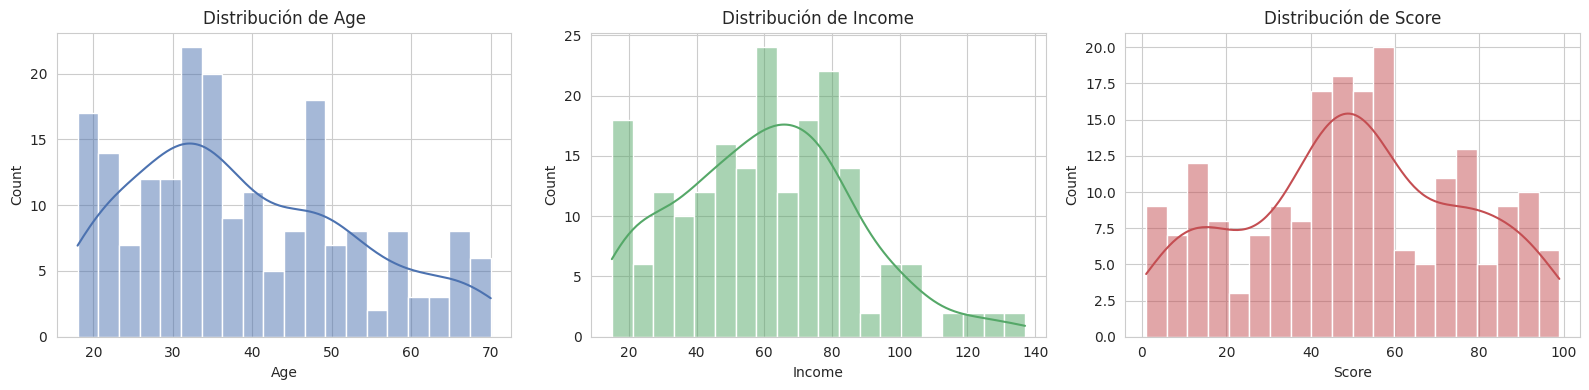

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, c in zip(axes, ["Age", "Income", "Score"], ["#4C72B0", "#55A868", "#C44E52"]):
    sns.histplot(df[col], kde=True, bins=20, ax=ax, color=c)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout(); plt.show()

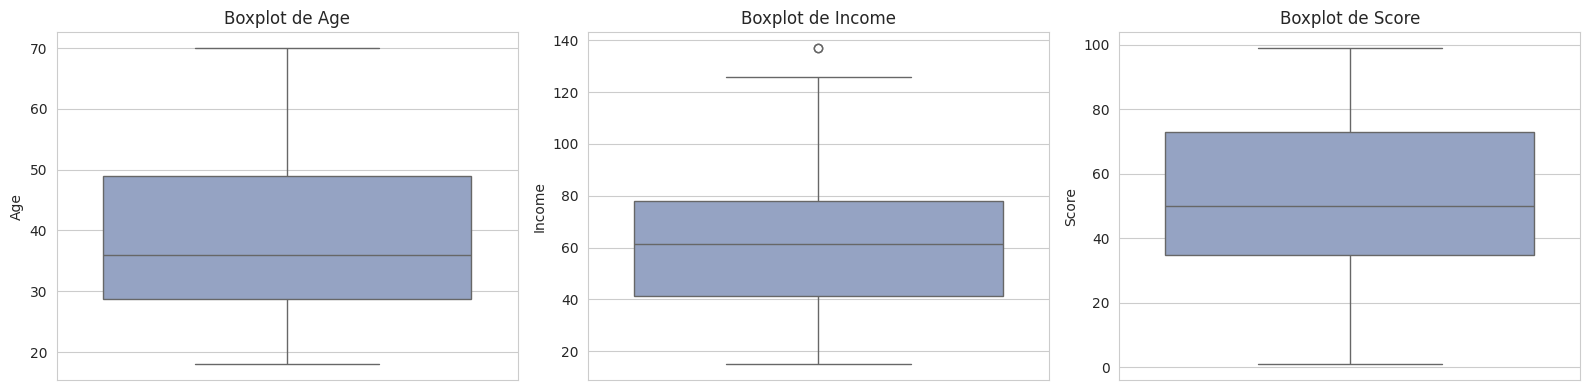

Age: límites [-1.6, 79.4] -> 0 atípicos []
Income: límites [-13.2, 132.8] -> 2 atípicos [137, 137]
Score: límites [-22.6, 130.4] -> 0 atípicos []


In [29]:
# Diagramas de caja para detectar valores atípicos
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Age", "Income", "Score"]):
    sns.boxplot(y=df[col], ax=ax, color="#8DA0CB")
    ax.set_title(f"Boxplot de {col}")
plt.tight_layout(); plt.show()

# Detección de atípicos con el criterio IQR
for col in ["Age", "Income", "Score"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: límites [{lim_inf:.1f}, {lim_sup:.1f}] -> {len(out)} atípicos {out[col].tolist()}")

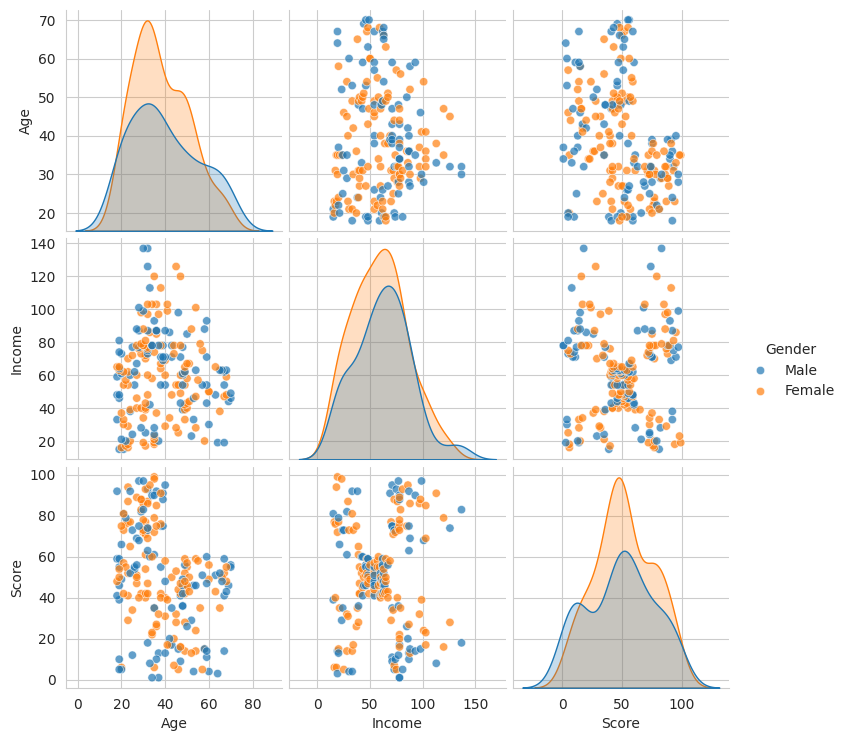

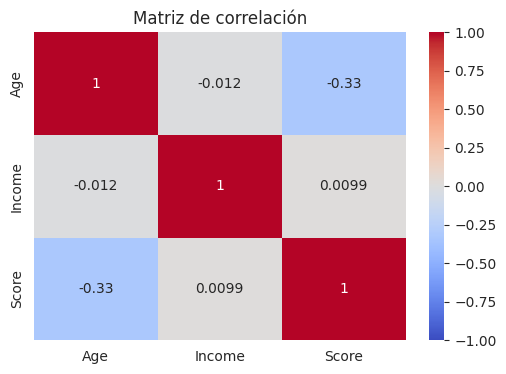

In [30]:
# Relaciones entre variables
sns.pairplot(df, vars=["Age", "Income", "Score"], hue="Gender", diag_kind="kde",
             plot_kws={"alpha": 0.7})
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df[["Age", "Income", "Score"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación"); plt.show()

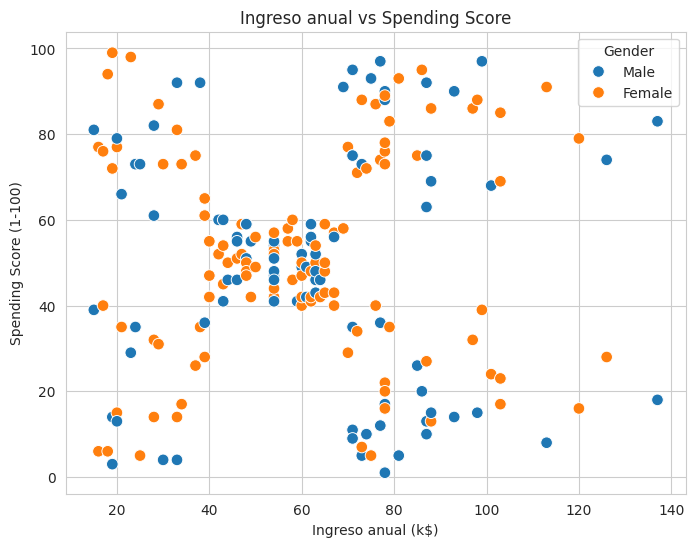

In [31]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Income", y="Score", hue="Gender", s=70)
plt.title("Ingreso anual vs Spending Score")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Spending Score (1-100)")
plt.show()

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

Las variables más adecuadas son **Ingreso anual (`Income`)** y **Spending Score (`Score`)**. Juntas describen *cuánto puede gastar* el cliente y *cuánto gasta realmente*, que es exactamente lo que necesita el área de marketing. En el gráfico de dispersión Ingreso vs Score se observan a simple vista cinco nubes de puntos bien separadas, lo que confirma que estas dos variables tienen estructura de grupos. `Age` es útil como variable descriptiva (para perfilar los clusters después), pero al incluirla los grupos se separan peor. `CustomerID` se descarta por ser un identificador y `Gender` porque es binaria y su distribución en Income/Score es prácticamente igual para hombres y mujeres.

**¿Se identifican valores atípicos?**

Prácticamente no. Según el criterio IQR, `Age` y `Score` no tienen atípicos y `Income` solo presenta un cliente por encima del límite superior (ingreso de 137 k$, que aparece dos veces). No es un error de captura sino un cliente de ingreso alto real, por lo que **se conserva**: eliminarlo quitaría información del segmento de altos ingresos y su efecto sobre los centroides es pequeño.

**¿Qué tipo de relaciones se observan entre las variables?**

- **Income vs Score:** correlación lineal casi nula (≈ 0.01), pero existe una relación **no lineal en forma de grupos**: hay clientes de ingreso medio con gasto medio en el centro, y en los ingresos bajos y altos se separan clientes que gastan mucho y clientes que gastan poco (forma de "X" o cruz). Esto es justamente lo que K-Means puede aprovechar.
- **Age vs Score:** correlación negativa moderada (≈ −0.33): los clientes jóvenes tienden a tener un Spending Score más alto; después de los 40 años casi no aparecen scores altos.
- **Age vs Income:** correlación prácticamente nula (≈ −0.01).
- El género no cambia de forma importante las distribuciones (hay un poco más de mujeres: 112 vs 88).

## Parte 2 – Preprocesamiento
Se seleccionan las variables `Income` y `Score` y se normalizan con `StandardScaler` (media 0, desviación estándar 1).

In [32]:
features = ["Income", "Score"]
X = df[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Antes de escalar  -> media:", X.mean(axis=0).round(2), " desv:", X.std(axis=0).round(2))
print("Después de escalar-> media:", X_scaled.mean(axis=0).round(2), " desv:", X_scaled.std(axis=0).round(2))
pd.DataFrame(X_scaled, columns=[f + "_esc" for f in features]).head()

Antes de escalar  -> media: [60.56 50.2 ]  desv: [26.2  25.76]
Después de escalar-> media: [-0. -0.]  desv: [1. 1.]


,Income_esc,Score_esc
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**, y esa distancia depende directamente de la escala de cada variable. Si una variable se mide en un rango grande (por ejemplo ingresos de 15 a 137) y otra en un rango menor, la de mayor rango domina el cálculo de la distancia y el algoritmo prácticamente ignora a las demás. Con `StandardScaler` cada variable queda con media 0 y desviación estándar 1, de modo que **todas aportan por igual** a la distancia, los clusters reflejan la estructura real de los datos y no las unidades de medida. Además, el escalado hace que métricas como la inercia y la silueta sean comparables y ayuda a que el algoritmo converja de manera más estable.

## Parte 3 – Método del codo

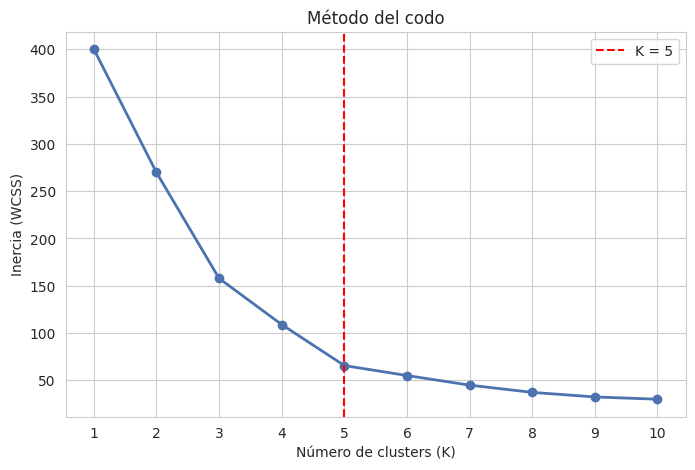

,K,Inercia,Reducción %
0,1,400.00,NaN
1,2,269.69,32.6
2,3,157.70,41.5
3,4,108.92,30.9
4,5,65.57,39.8
5,6,55.06,16.0
6,7,44.86,18.5
7,8,37.23,17.0
8,9,32.39,13.0
9,10,29.98,7.4


In [33]:
K_range = range(1, 11)
inercias = []
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inercias, "o-", color="#4C72B0", linewidth=2)
plt.axvline(5, color="red", linestyle="--", label="K = 5")
plt.title("Método del codo")
plt.xlabel("Número de clusters (K)"); plt.ylabel("Inercia (WCSS)")
plt.xticks(K_range); plt.legend(); plt.show()

pd.DataFrame({"K": list(K_range), "Inercia": np.round(inercias, 2),
              "Reducción %": np.round(-pd.Series(inercias).pct_change().values * 100, 1)})

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La gráfica del codo muestra la **inercia o WCSS** (*Within-Cluster Sum of Squares*): la suma de las distancias al cuadrado de cada punto a su centroide. Si la inercia es cercana a cero, los puntos están muy pegados a su centroide, es decir, los clusters son **compactos y homogéneos**: cada centroide representa muy bien a sus clientes. Por eso, a menor inercia, mejor ajuste interno.

Hay una advertencia: la inercia **siempre disminuye** al aumentar K y llega a 0 cuando K = n (cada punto es su propio cluster), lo que no sirve para nada. Por eso no se elige el K con la menor inercia, sino el punto donde agregar más clusters deja de reducirla significativamente.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **"codo"** de la curva: el valor de K a partir del cual la curva deja de caer bruscamente y se vuelve casi plana. Antes del codo, cada cluster adicional reduce mucho la inercia (se están separando grupos reales); después del codo, la reducción es marginal (se están partiendo grupos que ya eran homogéneos). En la tabla de reducción porcentual se ve que la inercia cae fuerte hasta **K = 5** y desde K = 6 las reducciones son mucho menores, por lo que el codo está en **K = 5**.

## Parte 4 – Coeficiente de silueta

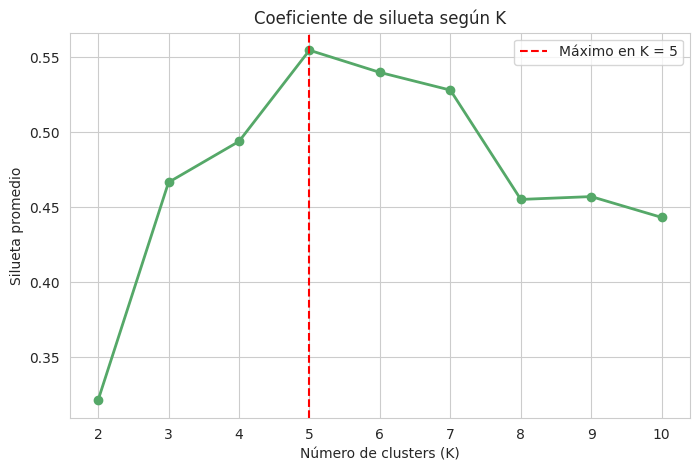

K óptimo según silueta: 5


,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


In [34]:
sil_scores = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels)

sil_df = pd.DataFrame({"K": list(sil_scores.keys()), "Silueta": np.round(list(sil_scores.values()), 4)})
k_opt_sil = max(sil_scores, key=sil_scores.get)

plt.figure(figsize=(8, 5))
plt.plot(sil_df["K"], sil_df["Silueta"], "o-", color="#55A868", linewidth=2)
plt.axvline(k_opt_sil, color="red", linestyle="--", label=f"Máximo en K = {k_opt_sil}")
plt.title("Coeficiente de silueta según K")
plt.xlabel("Número de clusters (K)"); plt.ylabel("Silueta promedio")
plt.legend(); plt.show()

print("K óptimo según silueta:", k_opt_sil)
sil_df

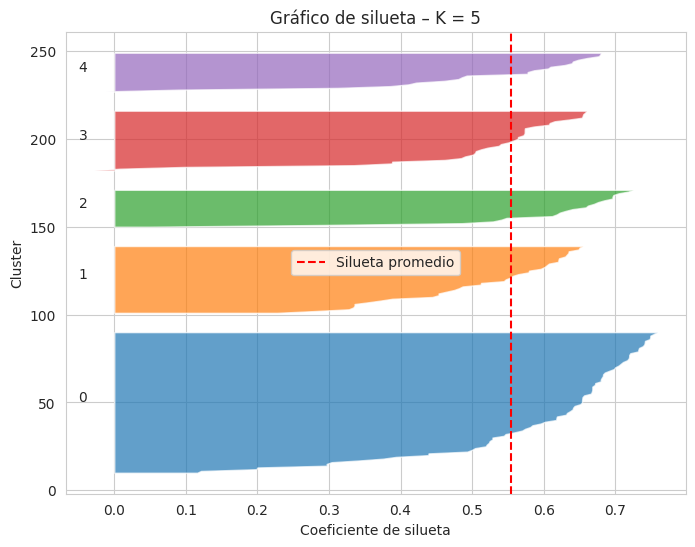

Observaciones con silueta negativa: 2


In [35]:
# Gráfico de silueta por observación para K = 5
k = 5
km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
labels = km.fit_predict(X_scaled)
valores = silhouette_samples(X_scaled, labels)

fig, ax = plt.subplots(figsize=(8, 6))
y_low = 10
for i in range(k):
    v = np.sort(valores[labels == i])
    y_up = y_low + len(v)
    ax.fill_betweenx(np.arange(y_low, y_up), 0, v, alpha=0.7)
    ax.text(-0.05, y_low + len(v) / 2, str(i))
    y_low = y_up + 10
ax.axvline(silhouette_score(X_scaled, labels), color="red", linestyle="--", label="Silueta promedio")
ax.set_title("Gráfico de silueta – K = 5"); ax.set_xlabel("Coeficiente de silueta"); ax.set_ylabel("Cluster")
ax.legend(); plt.show()
print("Observaciones con silueta negativa:", (valores < 0).sum())

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**

Mide qué tan bien asignado está cada punto a su cluster comparando **cohesión** y **separación**. Para cada observación *i*:

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}$$

donde *a(i)* es la distancia promedio de *i* a los demás puntos de su propio cluster y *b(i)* es la distancia promedio de *i* a los puntos del cluster vecino más cercano. Toma valores entre −1 y 1, y el promedio de todos los puntos resume la calidad global de la segmentación. A diferencia de la inercia, **no mejora automáticamente al aumentar K**, por lo que sirve para elegir K de forma objetiva.

**¿Qué significa un valor cercano a 1?**

Que el punto está mucho más cerca de los miembros de su propio cluster que de los del cluster vecino (*a(i)* ≪ *b(i)*). Los clusters son compactos y están bien separados entre sí: la asignación es clara y confiable.

**¿Qué implica un valor cercano a 0 o negativo?**

- **Cercano a 0:** el punto está en la **frontera** entre dos clusters (*a(i)* ≈ *b(i)*); los grupos se solapan y la asignación es ambigua.
- **Negativo:** el punto está, en promedio, más cerca de otro cluster que del suyo, es decir, probablemente está **mal asignado**. Un promedio general cercano a 0 o negativo indica que el número de clusters no es adecuado o que los datos no tienen una estructura de grupos clara.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

**Sí.** El coeficiente de silueta alcanza su máximo en **K = 5** (≈ 0.555), el mismo valor que señala el codo. Ambos métodos se complementan: el codo indica que a partir de K = 5 agregar clusters ya no reduce la inercia de forma importante, y la silueta confirma que con K = 5 los grupos son a la vez compactos y bien separados (para K = 4 y K = 6 la silueta es menor). Además, en el gráfico de silueta por observación todos los clusters superan el promedio y casi no hay valores negativos. Esto también coincide con lo observado visualmente en el diagrama Ingreso vs Score, donde se distinguen cinco nubes de puntos. Por lo tanto se elige **K = 5**.

## Parte 5 – Modelo K-Means

In [36]:
K_OPT = 5
kmeans = KMeans(n_clusters=K_OPT, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Centroides en escala original (deshaciendo el escalado)
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroides.index.name = "Cluster"
print("Centroides (escala original):")
centroides.round(2)

Centroides (escala original):


,Income,Score
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


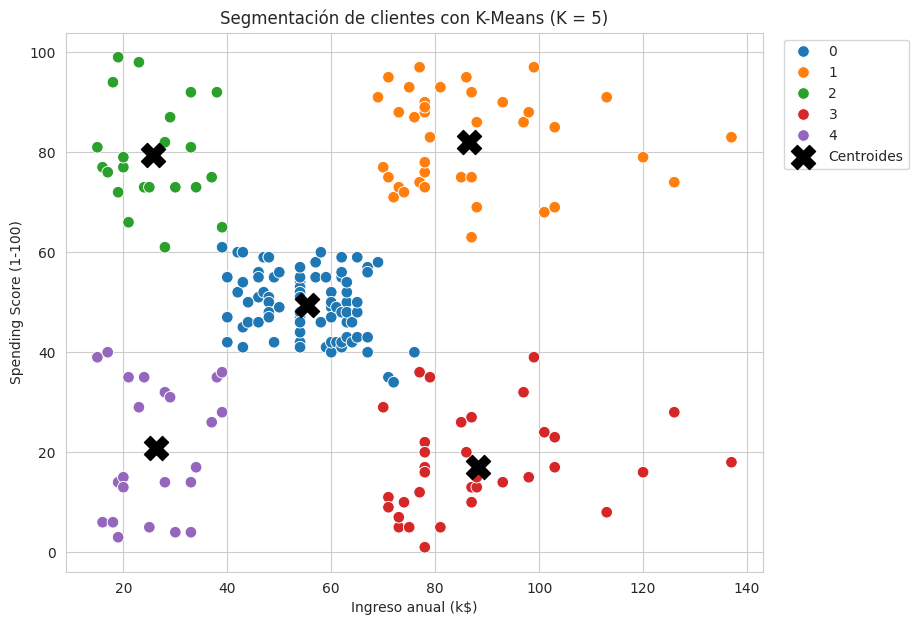

In [37]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x="Income", y="Score", hue="Cluster", palette="tab10", s=70)
plt.scatter(centroides["Income"], centroides["Score"], c="black", s=300, marker="X", label="Centroides")
plt.title("Segmentación de clientes con K-Means (K = 5)")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Spending Score (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

In [38]:
# Perfil de cada cluster
resumen = df.groupby("Cluster").agg(
    Clientes=("CustomerID", "count"),
    Edad_media=("Age", "mean"),
    Ingreso_medio=("Income", "mean"),
    Score_medio=("Score", "mean"),
    Pct_mujeres=("Gender", lambda g: (g == "Female").mean() * 100),
).round(1)
resumen["% del total"] = (resumen["Clientes"] / len(df) * 100).round(1)
resumen

,Clientes,Edad_media,Ingreso_medio,Score_medio,Pct_mujeres,% del total
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,40.5
1,39,32.7,86.5,82.1,53.8,19.5
2,22,25.3,25.7,79.4,59.1,11.0
3,35,41.1,88.2,17.1,45.7,17.5
4,23,45.2,26.3,20.9,60.9,11.5


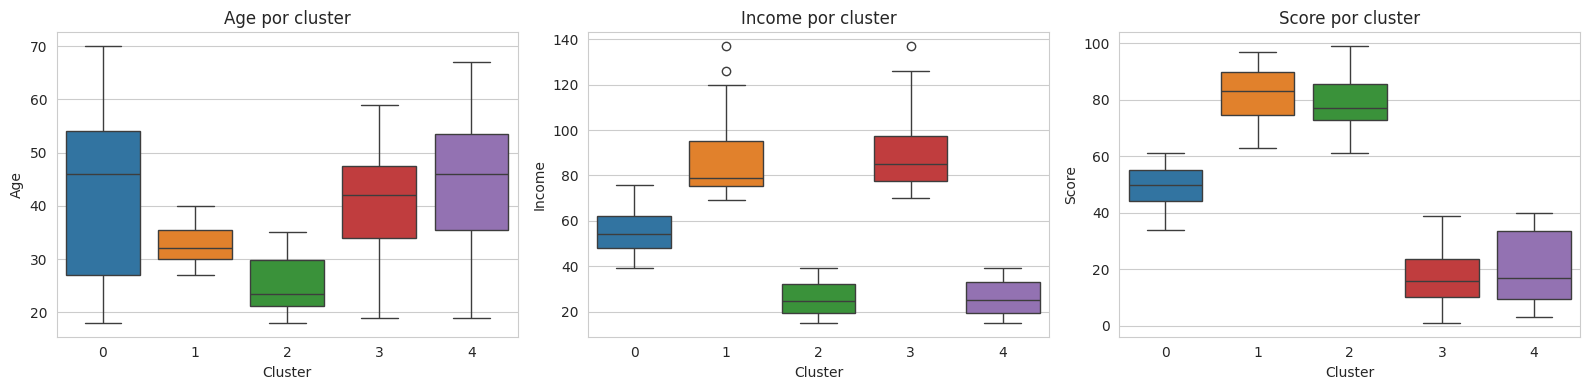

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Age", "Income", "Score"]):
    sns.boxplot(data=df, x="Cluster", y=col, palette="tab10", ax=ax)
    ax.set_title(f"{col} por cluster")
plt.tight_layout(); plt.show()

### Preguntas – Parte 5

*(La numeración de los clusters la asigna el algoritmo; la interpretación se basa en los centroides de la tabla anterior.)*

**¿Qué representa cada cluster?**

Cada cluster es un grupo de clientes con **ingreso y comportamiento de gasto similares**, y su centroide es el "cliente típico" del grupo:

1. **Ingreso alto – gasto alto** (≈ 87 k$, score ≈ 82; ~39 clientes): clientes de entre 25 y 40 años aprox. (edad media ≈ 33), con alto poder adquisitivo y que efectivamente lo gastan en el centro comercial.
2. **Ingreso alto – gasto bajo** (≈ 88 k$, score ≈ 17; ~35 clientes): tienen capacidad de compra pero gastan poco; edad media ≈ 41 años.
3. **Ingreso medio – gasto medio** (≈ 55 k$, score ≈ 50; ~81 clientes): el grupo más numeroso (≈ 40 %), con un rango de edad muy amplio (edad media ≈ 43).
4. **Ingreso bajo – gasto alto** (≈ 26 k$, score ≈ 79; ~22 clientes): clientes jóvenes (edad media ≈ 25) que gastan más de lo que su ingreso sugeriría.
5. **Ingreso bajo – gasto bajo** (≈ 26 k$, score ≈ 21; ~23 clientes): poco ingreso y poco gasto; edad media ≈ 45.

**¿Qué diferencias existen entre los grupos obtenidos?**

- **Ingreso:** se forman tres niveles (bajo ≈ 26 k$, medio ≈ 55 k$, alto ≈ 87 k$). Dentro de los niveles bajo y alto el gasto separa a los clientes en dos grupos opuestos, lo que demuestra que **el ingreso por sí solo no explica el gasto**.
- **Gasto:** la diferencia más marcada es entre los dos grupos de ingreso alto: tienen el mismo ingreso pero su score difiere en más de 60 puntos.
- **Edad (variable no usada en el modelo):** los grupos de gasto alto son claramente más jóvenes (≈ 25–33 años) que los de gasto bajo (≈ 41–45 años), confirmando la correlación negativa edad–score de la Parte 1.
- **Tamaño:** el segmento medio concentra casi el 40 % de los clientes, mientras que los segmentos extremos tienen entre 22 y 39 clientes cada uno.
- **Género:** la proporción de hombres y mujeres es similar en todos los grupos, por lo que no es un factor diferenciador.

## Parte 6 – Interpretación de negocio

In [40]:
# Asignación automática de perfiles según la posición del centroide
ing_med, sco_med = df["Income"].median(), df["Score"].median()

def perfil(c):
    ing, sco = c["Income"], c["Score"]
    if abs(ing - ing_med) < 15 and abs(sco - sco_med) < 15:
        return "Clientes promedio"
    if ing >= ing_med and sco >= sco_med:
        return "Clientes de alto valor"
    if ing >= ing_med and sco < sco_med:
        return "Clientes con potencial"
    if ing < ing_med and sco >= sco_med:
        return "Clientes de alto valor (impulsivos / bajo ingreso)"
    return "Clientes de bajo valor"

centroides["Perfil"] = centroides.apply(perfil, axis=1)
perfiles = centroides["Perfil"].to_dict()
df["Perfil"] = df["Cluster"].map(perfiles)

tabla_perfiles = resumen.join(centroides["Perfil"])
tabla_perfiles

,Clientes,Edad_media,Ingreso_medio,Score_medio,Pct_mujeres,% del total,Perfil
Cluster,,,,,,,
0,81,42.7,55.3,49.5,59.3,40.5,Clientes promedio
1,39,32.7,86.5,82.1,53.8,19.5,Clientes de alto valor
2,22,25.3,25.7,79.4,59.1,11.0,Clientes de alto valor (impulsivos / bajo ingr...
3,35,41.1,88.2,17.1,45.7,17.5,Clientes con potencial
4,23,45.2,26.3,20.9,60.9,11.5,Clientes de bajo valor


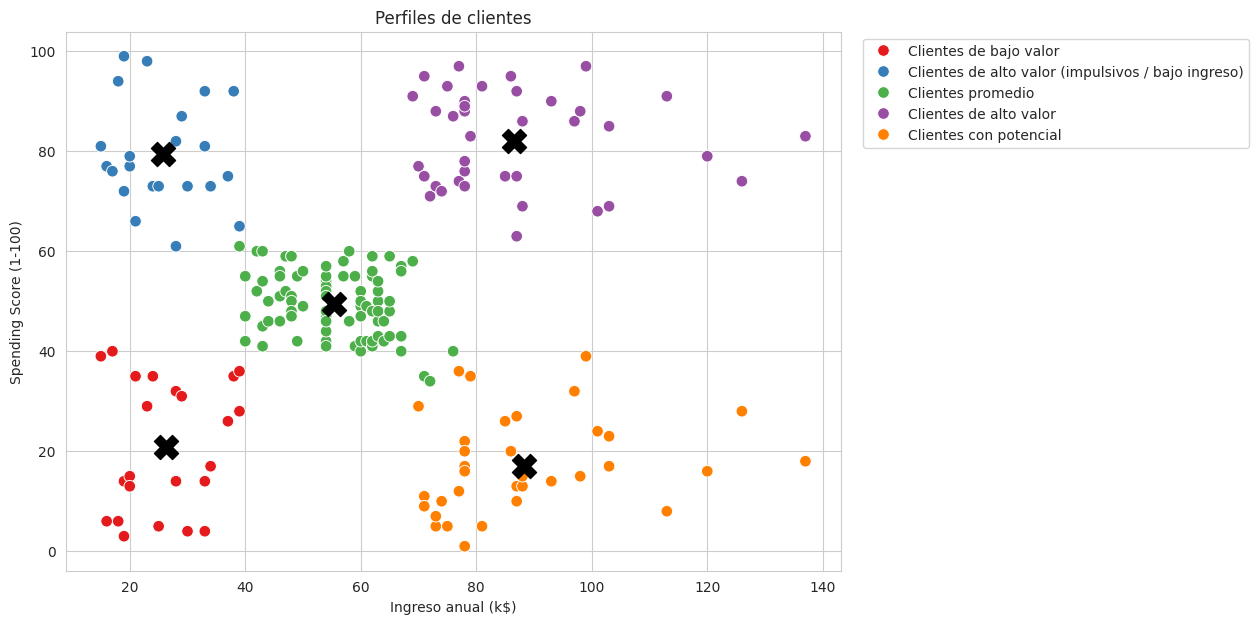

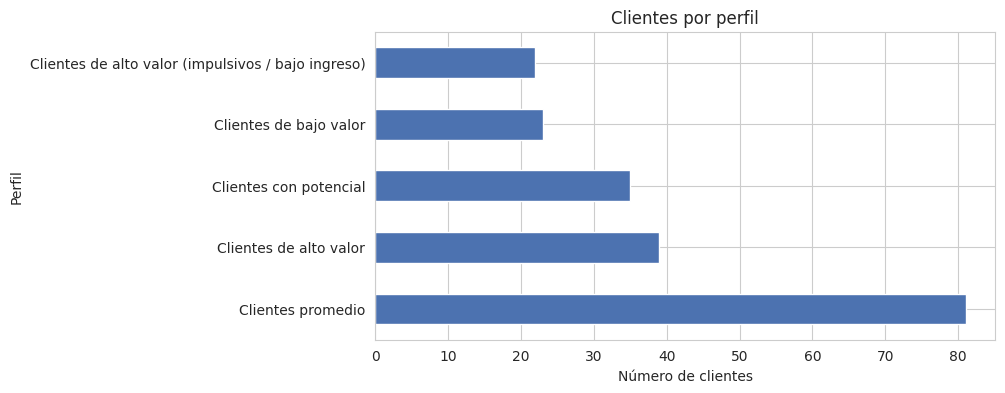

In [41]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x="Income", y="Score", hue="Perfil", palette="Set1", s=70)
plt.scatter(centroides["Income"], centroides["Score"], c="black", s=300, marker="X")
plt.title("Perfiles de clientes")
plt.xlabel("Ingreso anual (k$)"); plt.ylabel("Spending Score (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

df["Perfil"].value_counts().plot(kind="barh", color="#4C72B0", figsize=(8, 4), title="Clientes por perfil")
plt.xlabel("Número de clientes"); plt.show()

### Clasificación de los clusters en perfiles

| Segmento (centroide) | Perfil | Descripción |
|---|---|---|
| Ingreso alto – gasto alto | **Clientes de alto valor** | Los más rentables: ingreso y gasto altos, jóvenes-adultos. |
| Ingreso medio – gasto medio | **Clientes promedio** | La base estable del negocio (≈ 40 % de los clientes). |
| Ingreso alto – gasto bajo | **Clientes con potencial** | Tienen dinero pero no lo gastan en el centro comercial. |
| Ingreso bajo – gasto bajo | **Clientes de bajo valor** | Bajo ingreso y bajo gasto; aportan poco a la facturación. |
| Ingreso bajo – gasto alto | **Alto valor por gasto / riesgo** | Jóvenes que gastan mucho para su ingreso: valiosos hoy, pero sensibles al precio. |

### Preguntas – Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

- **Alto valor (ingreso alto – gasto alto):** *fidelizar y retener.* Programa de lealtad premium (tarjeta VIP, acumulación de puntos), atención personalizada, preventas y eventos exclusivos, lanzamientos de marcas de lujo. El objetivo es que no se vayan a la competencia y aumentar su frecuencia.
- **Promedio (ingreso medio – gasto medio):** *aumentar el ticket promedio.* Promociones por temporada, combos y descuentos por volumen, venta cruzada (*cross-selling*) entre tiendas del centro comercial, campañas masivas por redes sociales y correo, programa de puntos que los motive a subir de nivel.
- **Con potencial (ingreso alto – gasto bajo):** *activar el gasto.* Investigar por qué no compran (encuestas), ofrecer experiencias de calidad (gastronomía, entretenimiento, servicios de conveniencia como parqueadero o personal shopper), marcas premium y productos de valor diferencial más que descuentos, comunicación personalizada según sus intereses.
- **Ingreso bajo – gasto alto:** *mantener sin sobreexponer.* Promociones en tendencias y moda juvenil, alianzas con marcas para jóvenes, presencia en redes sociales e *influencers*, opciones de pago a plazos y descuentos para estudiantes; vigilar su sensibilidad al precio.
- **Bajo valor (ingreso bajo – gasto bajo):** *bajo costo de atención.* Promociones de precio, ofertas de productos básicos, días de descuento y cupones digitales; no invertir mucho presupuesto de marketing en este grupo, sino canales masivos y económicos.

**¿Qué segmento representa mayor oportunidad de crecimiento?**

El segmento de **ingreso alto – gasto bajo ("Clientes con potencial")**. Tiene prácticamente el mismo ingreso que los clientes de alto valor (≈ 88 k$ frente a ≈ 87 k$), pero gasta unos 65 puntos menos de Spending Score. Es decir, **la capacidad de compra ya existe** y la brecha entre lo que podrían gastar y lo que gastan es la mayor de todos los grupos. Convertir aunque sea una parte de estos ~35 clientes al comportamiento del segmento de alto valor generaría un aumento importante en ventas, sin depender de su capacidad económica. El segmento promedio es la segunda oportunidad por su tamaño (≈ 40 % de los clientes), ya que pequeños incrementos en su gasto tienen gran impacto agregado.

## Parte 7 – Despliegue con Streamlit

La aplicación está publicada en **Streamlit Community Cloud** a partir del repositorio de GitHub del proyecto:

### 👉 [Abrir la aplicación: https://segmentacion-clientes-kmeans.streamlit.app](https://segmentacion-clientes-kmeans.streamlit.app)

- **Código fuente:** [github.com/JuanMaya8/segmentacion_clientes](https://github.com/JuanMaya8/segmentacion_clientes) (archivo `app.py`)
- La aplicación carga el *Mall Customers Dataset*, escala `Income` y `Score` con `StandardScaler` y entrena K-Means con **K = 5**

### ¿Qué se encuentra en la página?

En la parte superior se muestran tres indicadores: el número de clientes analizados (200), el número de clusters (K = 5) y el coeficiente de silueta del modelo. Debajo hay tres pestañas:

**1. 📉 Método del codo**
- Gráfica de la inercia (WCSS) para K = 1 a 10, con una línea roja en K = 5 donde se forma el codo.
- Gráfica del coeficiente de silueta para K = 2 a 10, cuyo máximo también está en K = 5.
- Tabla con los valores de inercia y silueta de cada K, para comparar ambos métodos.

**2. 🎯 Clusters**
- Diagrama de dispersión Ingreso anual vs Spending Score con cada cliente coloreado según su cluster y los centroides marcados con una ✖.
- La leyenda indica el perfil de negocio de cada cluster (alto valor, promedio, con potencial, bajo valor, alto gasto con bajo ingreso).
- Tabla resumen por cluster: número de clientes, edad media, ingreso medio, Spending Score medio y perfil.

**3. 🧑 Clasificar nuevo cliente**
- Se ingresa el **ingreso anual (k$)** y se elige el **Spending Score (1-100)** con un deslizador.
- Al pulsar **"Clasificar cliente"**, la aplicación escala los datos con el mismo `StandardScaler`, usa `kmeans.predict()` para asignar el cluster más cercano y muestra el cluster y el perfil del cliente.
- El nuevo cliente aparece como una ⭐ roja sobre el gráfico de clusters, para ver en qué grupo cae.

**Ejemplos para probar:** ingreso 120 y score 90 → *Clientes de alto valor*; ingreso 120 y score 10 → *Clientes con potencial*; ingreso 55 y score 50 → *Clientes promedio*; ingreso 20 y score 85 → *Alto gasto con bajo ingreso*; ingreso 20 y score 10 → *Clientes de bajo valor*.

> **Abre el enlace de la aplicación** para recorrer las tres pestañas y clasificar tus propios clientes.

## Conclusiones

- Las variables **Ingreso anual** y **Spending Score** permiten una segmentación clara; la edad sirve para perfilar los grupos.
- El escalado con `StandardScaler` garantiza que ambas variables pesen igual en la distancia euclidiana.
- El **método del codo** y el **coeficiente de silueta** (≈ 0.55) coinciden en **K = 5**.
- Se identificaron cinco perfiles: alto valor, promedio, con potencial, bajo valor y jóvenes de gasto alto con bajo ingreso.
- El segmento con **mayor oportunidad de crecimiento** es el de **ingreso alto y gasto bajo**.
- La aplicación de Streamlit permite visualizar el modelo y clasificar nuevos clientes en tiempo real.